In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from medmnist import BloodMNIST

import sys
sys.path.insert(0, '../src')
from cellscope.config import CLASS_NAMES

sns.set_theme(style='whitegrid', font_scale=1.1)
SEED = 42
np.random.seed(SEED)

## 1. Load all splits

In [2]:
splits = {}
for split in ('train', 'val', 'test'):
    ds = BloodMNIST(split=split, download=False)
    splits[split] = {
        'images': np.array(ds.imgs),   # (N, 28, 28, 3)
        'labels': ds.labels.squeeze(), # (N,)
        'n': len(ds)
    }
    print(f"{split:>5}: {splits[split]['n']:>6} samples  "
          f"images shape: {splits[split]['images'].shape}  "
          f"dtype: {splits[split]['images'].dtype}")

train:  11959 samples  images shape: (11959, 28, 28, 3)  dtype: uint8
  val:   1712 samples  images shape: (1712, 28, 28, 3)  dtype: uint8
 test:   3421 samples  images shape: (3421, 28, 28, 3)  dtype: uint8


## 2. Class distribution

In [3]:
rows = []
for split, data in splits.items():
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        count = int((data['labels'] == cls_idx).sum())
        rows.append({'split': split, 'class': cls_name, 'count': count})

dist_df = pd.DataFrame(rows)
pivot = dist_df.pivot(index='class', columns='split', values='count')
pivot['total'] = pivot.sum(axis=1)
pivot['pct_of_total'] = (pivot['total'] / pivot['total'].sum() * 100).round(1)
print(pivot.sort_values('total', ascending=False).to_string())

split                  test  train  val  total  pct_of_total
class                                                       
Neutrophil              666   2330  333   3329          19.5
Eosinophil              624   2181  312   3117          18.2
Immature granulocytes   579   2026  290   2895          16.9
Platelet                470   1643  235   2348          13.7
Erythroblast            311   1085  155   1551           9.1
Monocyte                284    993  143   1420           8.3
Basophil                244    852  122   1218           7.1
Lymphocyte              243    849  122   1214           7.1


C:\Users\SADM-X265034\AppData\Local\Temp\2\ipykernel_13260\504888724.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dist_df[dist_df.split == 'train'],


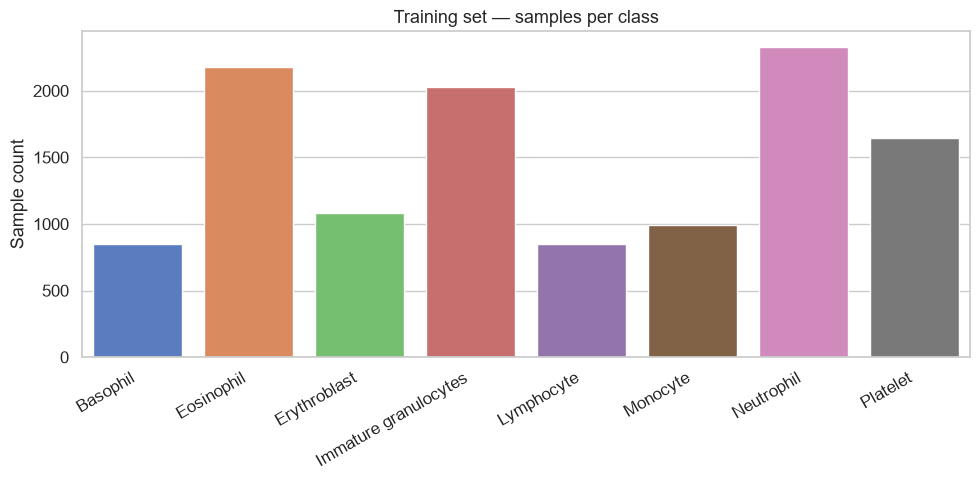

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=dist_df[dist_df.split == 'train'],
            x='class', y='count', ax=ax, palette='muted')
ax.set_title('Training set — samples per class')
ax.set_xlabel('')
ax.set_ylabel('Sample count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../reports/figures/class_distribution.png', dpi=150)
plt.show()

## 3. Example image grid — one row per class

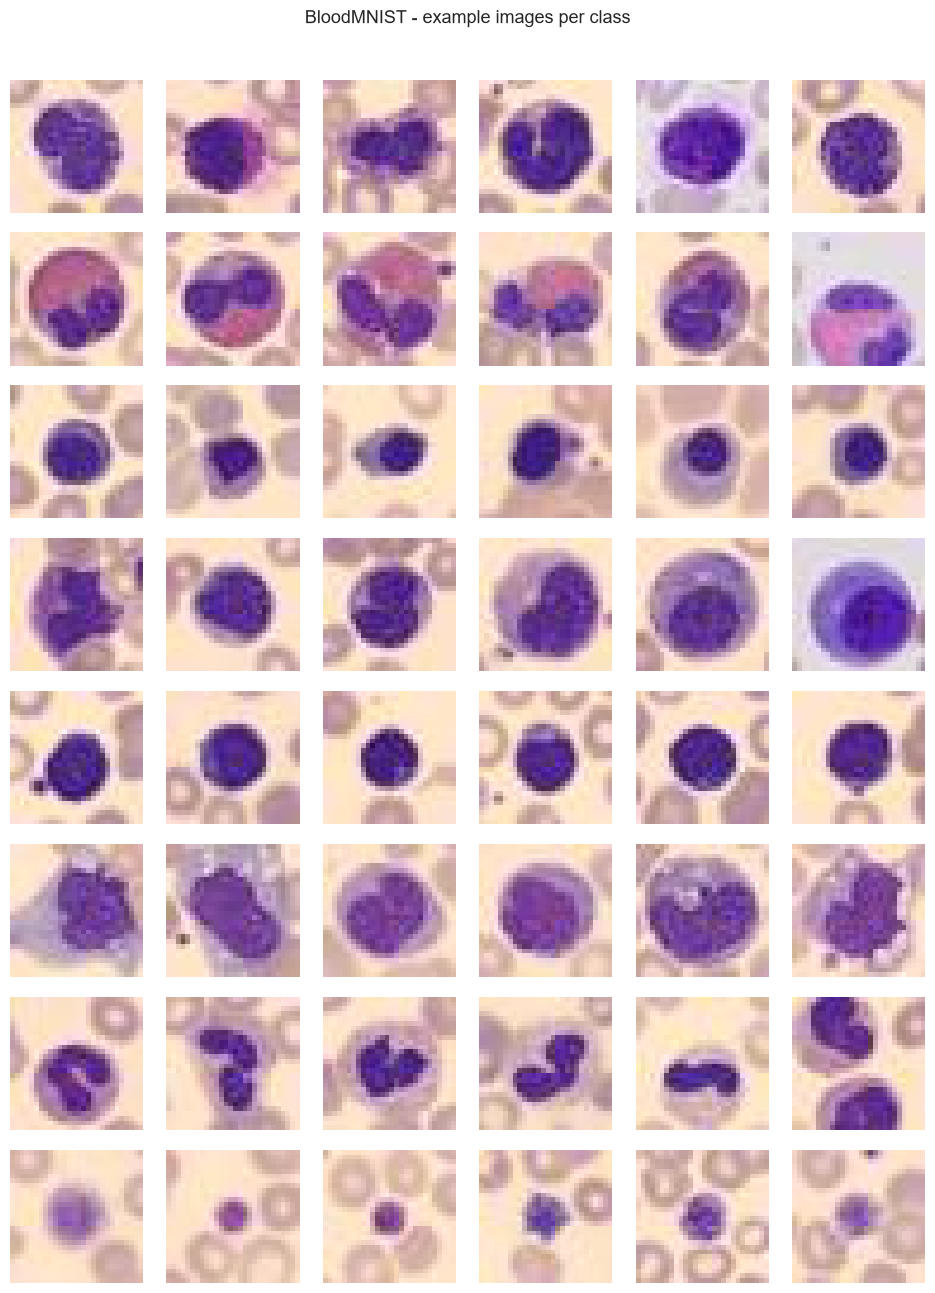

In [5]:
n_examples = 6
train_images = splits['train']['images']
train_labels = splits['train']['labels']

fig, axes = plt.subplots(len(CLASS_NAMES), n_examples,
                          figsize=(n_examples * 1.6, len(CLASS_NAMES) * 1.6))

for row, (cls_idx, cls_name) in enumerate(enumerate(CLASS_NAMES)):
    idxs = np.where(train_labels == cls_idx)[0]
    chosen = np.random.choice(idxs, n_examples, replace=False)
    for col, img_idx in enumerate(chosen):
        axes[row, col].imshow(train_images[img_idx])
        axes[row, col].axis('off')
    axes[row, 0].set_ylabel(cls_name, fontsize=9, rotation=0,
                             labelpad=80, va='center')

fig.suptitle('BloodMNIST - example images per class', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('../reports/figures/example_grid.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Pixel value distribution

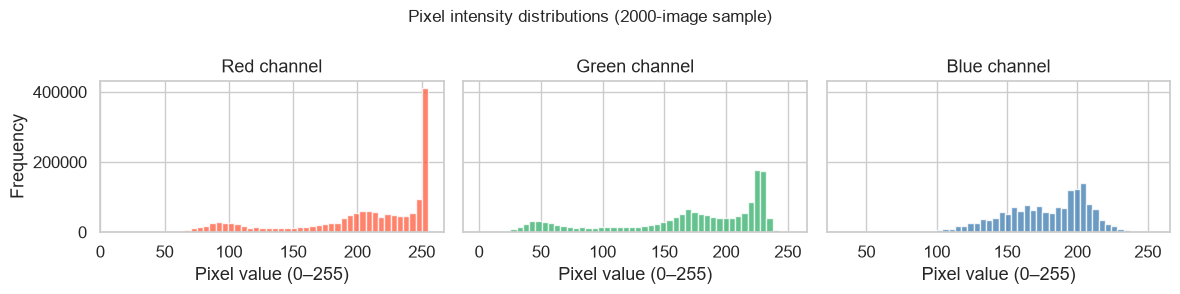

Per-channel mean : [203.1 168.1 177.5]
Per-channel std  : [54.8 61.3 29.9]
Global min/max   : 0 / 255


In [6]:
sample_idx = np.random.choice(len(train_images), 2000, replace=False)
sample = train_images[sample_idx].reshape(-1, 3).astype(np.float32)

fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
channel_names = ['Red', 'Green', 'Blue']
colors = ['tomato', 'mediumseagreen', 'steelblue']

for i, (name, color) in enumerate(zip(channel_names, colors)):
    axes[i].hist(sample[:, i], bins=50, color=color, alpha=0.8)
    axes[i].set_title(f'{name} channel')
    axes[i].set_xlabel('Pixel value (0–255)')

axes[0].set_ylabel('Frequency')
fig.suptitle('Pixel intensity distributions (2000-image sample)', fontsize=12)
plt.tight_layout()
plt.savefig('../reports/figures/pixel_distribution.png', dpi=150)
plt.show()

print(f"Per-channel mean : {sample.mean(axis=0).round(1)}")
print(f"Per-channel std  : {sample.std(axis=0).round(1)}")
print(f"Global min/max   : {sample.min():.0f} / {sample.max():.0f}")

## 5. Image properties validation

In [7]:
for split, data in splits.items():
    imgs = data['images']
    assert imgs.ndim == 4, f"{split}: expected 4D array"
    assert imgs.shape[1:] == (28, 28, 3), f"{split}: unexpected shape {imgs.shape[1:]}"
    assert imgs.dtype == np.uint8, f"{split}: unexpected dtype {imgs.dtype}"
    print(f"{split:>5}: shape={imgs.shape}  dtype={imgs.dtype}  "
          f"min={imgs.min()}  max={imgs.max()}  — OK")

train: shape=(11959, 28, 28, 3)  dtype=uint8  min=0  max=255  — OK
  val: shape=(1712, 28, 28, 3)  dtype=uint8  min=0  max=255  — OK
 test: shape=(3421, 28, 28, 3)  dtype=uint8  min=0  max=255  — OK


## 6. Class imbalance assessment

In [8]:
train_counts = pivot['train'].sort_values()
imbalance_ratio = train_counts.max() / train_counts.min()
print(f"Most common class : {train_counts.idxmax()} ({train_counts.max()} samples)")
print(f"Least common class: {train_counts.idxmin()} ({train_counts.min()} samples)")
print(f"Imbalance ratio   : {imbalance_ratio:.1f}x")

if imbalance_ratio > 3:
    print("\nNote: imbalance ratio > 3x — use balanced accuracy and macro F1 as primary metrics.")
else:
    print("\nClass balance is moderate. Standard accuracy is acceptable alongside macro F1.")

Most common class : Neutrophil (2330 samples)
Least common class: Lymphocyte (849 samples)
Imbalance ratio   : 2.7x

Class balance is moderate. Standard accuracy is acceptable alongside macro F1.


## 7. Summary

Fill in observations after running the notebook:

- **Split sizes:** train / val / test = (fill in)
- **Image format:** 28 × 28 RGB uint8, values 0–255
- **Class imbalance:** (fill in ratio and which classes are affected)
- **Pixel range:** appears to use full 0–255 range with staining variation
- **Limitations:** single imaging source, controlled conditions — may not generalise to other microscopes or staining protocols

**Action for training:** use balanced accuracy and macro F1 as primary metrics. Consider class weights in loss function if imbalance ratio exceeds 3×.